# Week 9 Jupyter Notebook – Gradient Boosting
## Predicting Loan Default with Boosted Trees

### Project Overview

For Week 9, I am continuing my credit-risk classification analysis using gradient boosting. Week 6 showed that a random forest performed well, so I wanted to see whether sequentially correcting prediction errors with boosted trees would improve default detection. I kept the same target and predictors so I could compare the results.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, silhouette_score, adjusted_rand_score)
pd.set_option('display.max_columns', None)

from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
# In Colab, upload credit_risk_dataset 2.csv if it is not already available.
try:
    df = pd.read_csv('credit_risk_dataset 2.csv')
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
print('Dataset shape:', df.shape)
display(df.head())


Saving credit_risk_dataset 2.csv to credit_risk_dataset 2.csv
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
target = 'loan_status'
continuous_features = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
data = df[continuous_features + categorical_features + [target]].dropna().copy()
print('Rows after removing missing values:', len(data))
print('Default rate:', round(data[target].mean(), 4))
X = data[continuous_features + categorical_features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Training observations:', len(X_train), 'Testing observations:', len(X_test))


Rows after removing missing values: 28638
Default rate: 0.2166
Training observations: 22910 Testing observations: 5728


## Data Preprocessing

Like the Week 6 tree models, gradient boosting does not require standardized numeric features. I encoded categorical features and left continuous predictors on their original scales. The preprocessing is fitted only on the training data.

In [ ]:
preprocessor = ColumnTransformer(transformers=[('continuous', 'passthrough', continuous_features), ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)])

## Baseline Gradient Boosting

I started with 100 trees, a learning rate of 0.1, and depth 3. The learning rate determines how much each new tree contributes, while tree depth controls the complexity of the relationships that each tree can learn.

In [ ]:
baseline = Pipeline([('preprocessor',preprocessor),('boost',GradientBoostingClassifier(random_state=42))])
baseline.fit(X_train,y_train)
base_pred=baseline.predict(X_test)
base_prob=baseline.predict_proba(X_test)[:,1]
print('Training accuracy:',round(baseline.score(X_train,y_train),4))
print('Testing accuracy:',round(accuracy_score(y_test,base_pred),4))
print('Recall:',round(recall_score(y_test,base_pred),4))
print('F1:',round(f1_score(y_test,base_pred),4))
print('ROC-AUC:',round(roc_auc_score(y_test,base_prob),4))

Training accuracy: 0.9245
Testing accuracy: 0.919
Recall: 0.6841
F1: 0.7854
ROC-AUC: 0.9232


## Hyperparameter Tuning and Overfitting

I compared the number of estimators, learning rate, and maximum depth using cross-validation. More trees and deeper trees can improve training fit but may overfit. I used cross-validated F1 to select a model rather than picking the highest test score.

In [ ]:
param_grid={'boost__n_estimators':[100,200], 'boost__learning_rate':[0.05,0.1], 'boost__max_depth':[2,3]}
search=GridSearchCV(Pipeline([('preprocessor',preprocessor),('boost',GradientBoostingClassifier(random_state=42))]),param_grid,cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42),scoring='f1',n_jobs=-1,return_train_score=True)
search.fit(X_train,y_train)
boost_results=pd.DataFrame(search.cv_results_)
print('Best parameters:',search.best_params_)
print('Best cross-validation F1:',round(search.best_score_,4))
display(boost_results[['param_boost__n_estimators','param_boost__learning_rate','param_boost__max_depth','mean_train_score','mean_test_score']].sort_values('mean_test_score',ascending=False).round(4))

Best parameters: {'boost__learning_rate': 0.1, 'boost__max_depth': 3, 'boost__n_estimators': 200}
Best cross-validation F1: 0.8154


,param_boost__n_estimators,param_boost__learning_rate,param_boost__max_depth,mean_train_score,mean_test_score
7,200,0.10,3,0.8302,0.8154
3,200,0.05,3,0.8058,0.7939
6,100,0.10,3,0.8062,0.7927
5,200,0.10,2,0.7927,0.7827
2,100,0.05,3,0.7733,0.7663
4,100,0.10,2,0.7644,0.7601
1,200,0.05,2,0.7634,0.7574
0,100,0.05,2,0.7252,0.7198


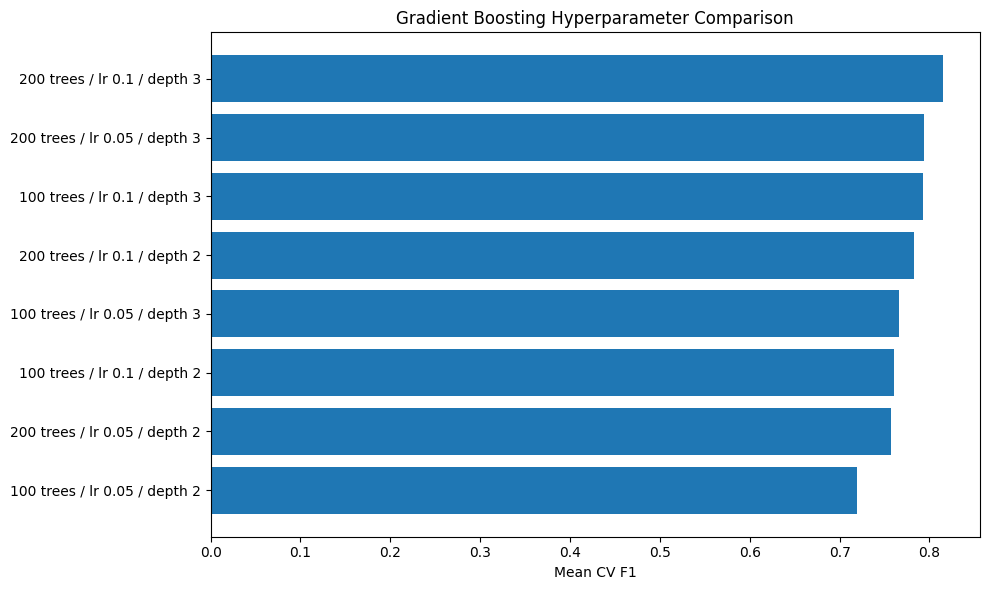

In [ ]:
plot_df=boost_results.sort_values('mean_test_score')
labels=[f"{int(r['param_boost__n_estimators'])} trees / lr {r['param_boost__learning_rate']} / depth {r['param_boost__max_depth']}" for _,r in plot_df.iterrows()]
plt.figure(figsize=(10,6));plt.barh(labels,plot_df['mean_test_score']);plt.xlabel('Mean CV F1');plt.title('Gradient Boosting Hyperparameter Comparison');plt.tight_layout();plt.show()

The best model used 200 estimators, a learning rate of 0.1, and a maximum depth of 3. It achieved a cross-validation F1 score of 0.8154. Increasing the number of trees allowed the model to make additional corrections to earlier predictions, while the learning rate controlled how much each tree contributed. Limiting tree depth helped control model complexity.

The tuned model reached 0.9340 training accuracy and 0.9255 testing accuracy. The difference was relatively small, suggesting that the model generalized well and did not show severe overfitting. Cross-validation also helped reduce the risk of selecting parameters that performed well on only one training split.

## Tuned Gradient Boosting

I evaluated the selected model on the test data. I also looked at the confusion matrix because false negatives are important in credit-risk modeling.

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Week 9 Tuned Gradient Boosting,0.934,0.9255,0.9434,0.6978,0.8022,0.9315


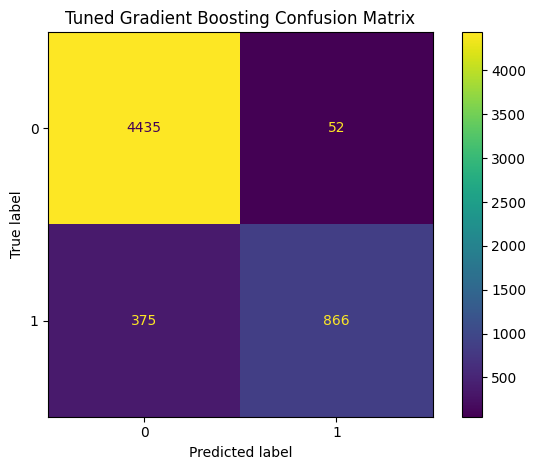

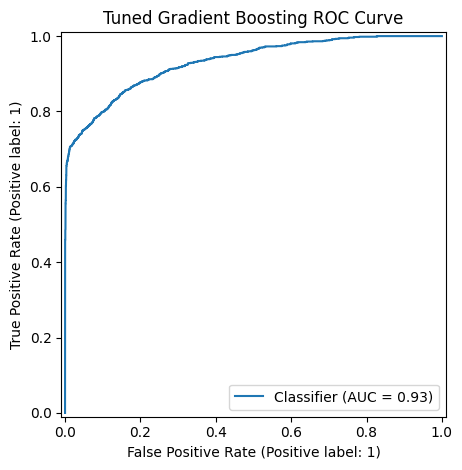

In [ ]:
best_boost=search.best_estimator_
boost_pred=best_boost.predict(X_test)
boost_prob=best_boost.predict_proba(X_test)[:,1]
boost_summary=pd.DataFrame([{'Model':'Week 9 Tuned Gradient Boosting','Train Accuracy':best_boost.score(X_train,y_train),'Test Accuracy':accuracy_score(y_test,boost_pred),'Precision':precision_score(y_test,boost_pred),'Recall':recall_score(y_test,boost_pred),'F1 Score':f1_score(y_test,boost_pred),'ROC-AUC':roc_auc_score(y_test,boost_prob)}])
display(boost_summary.round(4))
ConfusionMatrixDisplay.from_predictions(y_test,boost_pred);plt.title('Tuned Gradient Boosting Confusion Matrix');plt.tight_layout();plt.show()
RocCurveDisplay.from_predictions(y_test,boost_prob);plt.title('Tuned Gradient Boosting ROC Curve');plt.tight_layout();plt.show()

## Feature Importance

I looked at feature importance to understand which predictors the boosted trees used most often to reduce error. These scores do not show causation, but they can help identify patterns worth investigating.

,Feature,Importance
5,loan_percent_income,0.3148
4,loan_int_rate,0.2134
9,person_home_ownership_RENT,0.1592
1,person_income,0.1138
17,loan_grade_D,0.0476
2,person_emp_length,0.0260
8,person_home_ownership_OWN,0.0258
16,loan_grade_C,0.0256
11,loan_intent_HOMEIMPROVEMENT,0.0194
12,loan_intent_MEDICAL,0.0114


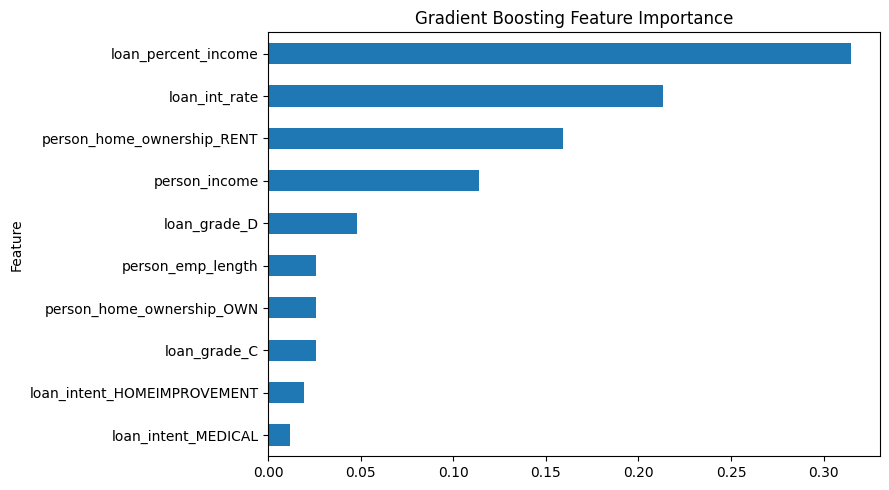

In [ ]:
names=best_boost.named_steps['preprocessor'].get_feature_names_out()
importance_df=pd.DataFrame({'Feature':[v.replace('continuous__','').replace('categorical__','') for v in names],'Importance':best_boost.named_steps['boost'].feature_importances_}).sort_values('Importance',ascending=False)
display(importance_df.head(10).round(4))
importance_df.head(10).sort_values('Importance').plot.barh(x='Feature',y='Importance',legend=False,figsize=(9,5));plt.title('Gradient Boosting Feature Importance');plt.tight_layout();plt.show()

Loan percent income was the most important feature (0.3148), followed by loan interest rate (0.2134), renting a home (0.1592), and person income (0.1138). I expected loan percent income and interest rate to be important because they relate to the financial burden of borrowing.

This was also consistent with Week 6, where loan percent income was the most important feature in the random forest. The importance values do not mean that these variables cause default, but they show which predictors contributed most to the model's decisions.

## Model Comparison and Conclusions

The tuned gradient boosting model achieved 0.9255 accuracy, 0.6978 recall, 0.8022 F1, and 0.9315 ROC-AUC. These results improved on the baseline gradient boosting model, which had an F1 score of 0.7854 and ROC-AUC of 0.9232.

Compared with the Week 6 random forest, gradient boosting performed slightly better in ROC-AUC (0.9315 versus 0.9282). However, the random forest had slightly higher recall (0.7010 versus 0.6978) and F1 (0.8093 versus 0.8022). This was interesting because gradient boosting improved the model's overall ability to distinguish defaults from non-defaults, but it did not improve every classification metric.

The relatively small difference between training and testing accuracy also suggested that the tuned model was not severely overfitting. Overall, gradient boosting was competitive with the random forest and provided another strong approach to predicting loan default. The better model depends on whether the priority is overall ranking performance or correctly identifying defaults at the chosen classification threshold.

,Model,Recall,F1 Score,ROC-AUC
0,Week 6 Random Forest,0.7010,0.8093,0.9282
1,Week 9 Gradient Boosting,0.6978,0.8022,0.9315


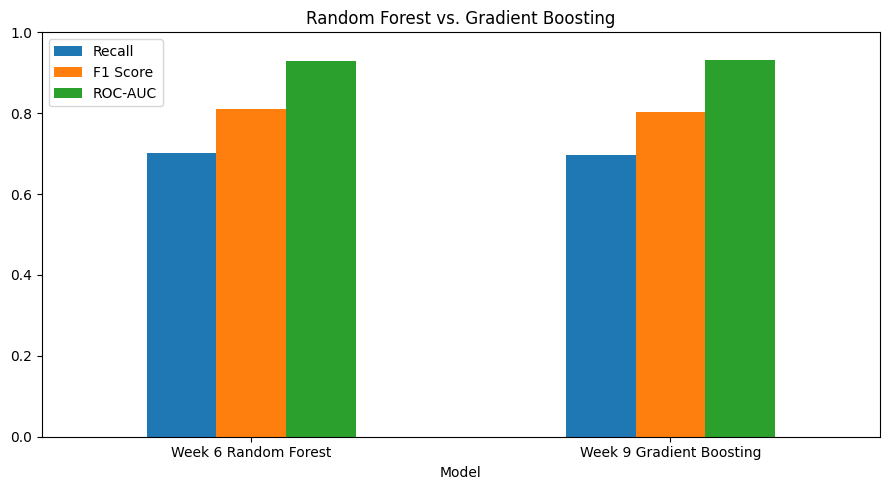

In [ ]:
comparison=pd.DataFrame([{'Model':'Week 6 Random Forest','Recall':0.7010,'F1 Score':0.8093,'ROC-AUC':0.9282},{'Model':'Week 9 Gradient Boosting','Recall':boost_summary.loc[0,'Recall'],'F1 Score':boost_summary.loc[0,'F1 Score'],'ROC-AUC':boost_summary.loc[0,'ROC-AUC']}])
display(comparison.round(4))
comparison.set_index('Model').plot.bar(figsize=(9,5),rot=0);plt.ylim(0,1);plt.title('Random Forest vs. Gradient Boosting');plt.tight_layout();plt.show()